# PredictX AI – Feature Engineering

**Project:** Machine Failure Prediction and Remaining Useful Life Estimation

This notebook prepares machine sensor data and creates useful features for future prediction.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

telemetry = pd.read_csv("/content/PdM_telemetry.csv")
machines = pd.read_csv("/content/PdM_machines.csv")
errors = pd.read_csv("/content/PdM_errors.csv")
failures = pd.read_csv("/content/PdM_failures.csv")
maintenance = pd.read_csv("/content/PdM_maint.csv")

print("All files loaded")

All files loaded


## 2. Check the data

In [2]:
print("Telemetry:", telemetry.shape)
print("Machines:", machines.shape)
print("Errors:", errors.shape)
print("Failures:", failures.shape)
print("Maintenance:", maintenance.shape)

Telemetry: (57900, 6)
Machines: (100, 3)
Errors: (3919, 3)
Failures: (761, 3)
Maintenance: (3286, 3)


In [3]:
display(telemetry.head())

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511


In [4]:
print(telemetry.columns)
print(telemetry.dtypes)

Index(['datetime', 'machineID', 'volt', 'rotate', 'pressure', 'vibration'], dtype='object')
datetime      object
machineID      int64
volt         float64
rotate       float64
pressure     float64
vibration    float64
dtype: object


In [5]:
print("Missing values:")
print(telemetry.isnull().sum())

Missing values:
datetime     0
machineID    0
volt         0
rotate       0
pressure     1
vibration    1
dtype: int64


In [6]:
print("Duplicate telemetry rows:", telemetry.duplicated().sum())
print("Duplicate machine rows:", machines.duplicated().sum())

Duplicate telemetry rows: 0
Duplicate machine rows: 0


In [7]:
display(telemetry[["volt", "rotate", "pressure", "vibration"]].describe())

,volt,rotate,pressure,vibration
count,57900.000000,57900.000000,57899.000000,57899.000000
mean,170.789483,446.789421,100.707348,40.410403
std,15.482517,52.607877,10.863982,5.343834
min,100.194137,174.126968,54.914013,19.955458
25%,160.340023,412.629205,93.475241,36.821854
50%,170.555036,447.871192,100.353377,40.270284
75%,181.006814,481.983282,107.348793,43.780565
max,241.516461,661.800282,182.111770,70.365920


## 3. Missing values

In [8]:
missing_count = telemetry.isnull().sum()
missing_percent = (missing_count / len(telemetry)) * 100

print("Missing count:")
print(missing_count)
print("Missing percentage:")
print(missing_percent.round(2))

Missing count:
datetime     0
machineID    0
volt         0
rotate       0
pressure     1
vibration    1
dtype: int64
Missing percentage:
datetime     0.0
machineID    0.0
volt         0.0
rotate       0.0
pressure     0.0
vibration    0.0
dtype: float64


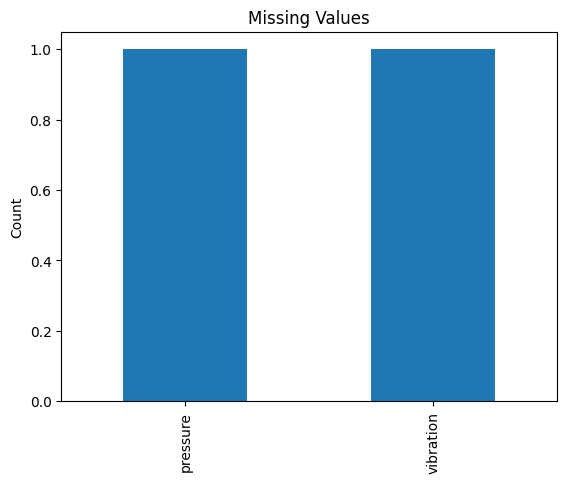

In [9]:
missing_count[missing_count > 0].plot(kind="bar")
plt.title("Missing Values")
plt.ylabel("Count")
plt.show()

## 4. Check outliers

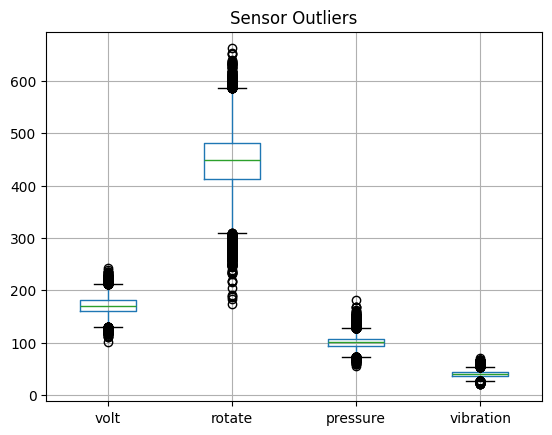

In [10]:
telemetry[["volt", "rotate", "pressure", "vibration"]].boxplot()
plt.title("Sensor Outliers")
plt.show()

In [11]:
# IQR method for vibration
q1 = telemetry["vibration"].quantile(0.25)
q3 = telemetry["vibration"].quantile(0.75)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

outliers = telemetry[(telemetry["vibration"] < lower_limit) | (telemetry["vibration"] > upper_limit)]
print("Possible vibration outliers:", len(outliers))

Possible vibration outliers: 730


## 5. Check categories

In [12]:
print(machines["model"].value_counts())
print(errors["errorID"].value_counts())
print(failures["failure"].value_counts())

model
model3    35
model4    32
model2    17
model1    16
Name: count, dtype: int64
errorID
error1    1010
error2     988
error3     838
error4     727
error5     356
Name: count, dtype: int64
failure
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64


## 6. Remove duplicates

In [13]:
telemetry = telemetry.drop_duplicates()
machines = machines.drop_duplicates()
errors = errors.drop_duplicates()
failures = failures.drop_duplicates()
maintenance = maintenance.drop_duplicates()

print("Duplicates removed")

Duplicates removed


## 7. Fill missing values

In [14]:
# Use the median for sensor numbers
sensor_columns = ["volt", "rotate", "pressure", "vibration"]
for column in sensor_columns:
    telemetry[column] = telemetry[column].fillna(telemetry[column].median())

print(telemetry[sensor_columns].isnull().sum())

volt         0
rotate       0
pressure     0
vibration    0
dtype: int64


In [15]:
# Use median for age and most common value for categories
machines["age"] = machines["age"].fillna(machines["age"].median())
machines["model"] = machines["model"].fillna(machines["model"].mode()[0])
errors["errorID"] = errors["errorID"].fillna(errors["errorID"].mode()[0])
failures["failure"] = failures["failure"].fillna(failures["failure"].mode()[0])
maintenance["comp"] = maintenance["comp"].fillna(maintenance["comp"].mode()[0])
print("Missing values filled")

Missing values filled


## 8. Combine data

In [16]:
# Convert date columns into date format
telemetry["datetime"] = pd.to_datetime(telemetry["datetime"])
errors["datetime"] = pd.to_datetime(errors["datetime"])
failures["datetime"] = pd.to_datetime(failures["datetime"])
maintenance["datetime"] = pd.to_datetime(maintenance["datetime"])

# Add machine model and age to sensor readings
df = pd.merge(telemetry, machines, on="machineID", how="left")
df = df.sort_values(["machineID", "datetime"])
print(df.shape)
display(df.head())

(57900, 8)


,datetime,machineID,volt,rotate,pressure,vibration,model,age
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,model3,18
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,model3,18
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,model3,18
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,model3,18
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,model3,18


## 9. Create time features

In [17]:
df["hour"] = df["datetime"].dt.hour
df["day_of_week"] = df["datetime"].dt.dayofweek
df["month"] = df["datetime"].dt.month

display(df[["datetime", "hour", "day_of_week", "month"]].head())

,datetime,hour,day_of_week,month
0,2015-01-01 06:00:00,6,3,1
1,2015-01-01 07:00:00,7,3,1
2,2015-01-01 08:00:00,8,3,1
3,2015-01-01 09:00:00,9,3,1
4,2015-01-01 10:00:00,10,3,1


## 10. Create sensor-change features

In [18]:
# Difference from the previous reading for the same machine
df["vibration_change"] = df.groupby("machineID")["vibration"].diff()
df["pressure_change"] = df.groupby("machineID")["pressure"].diff()
df["rotation_change"] = df.groupby("machineID")["rotate"].diff()

display(df[["machineID", "vibration", "vibration_change"]].head(10))

,machineID,vibration,vibration_change
0,1,45.087686,NaN
1,1,43.413973,-1.673713
2,1,34.178847,-9.235126
3,1,41.122144,6.943297
4,1,25.990511,-15.131633
5,1,35.655017,9.664506
6,1,42.753920,7.098902
7,1,35.482009,-7.271911
8,1,45.482287,10.000278
9,1,39.901735,-5.580551


## 11. Add machine error and maintenance counts

In [19]:
# Total recorded errors for each machine
error_counts = errors["machineID"].value_counts()
df["error_count"] = df["machineID"].map(error_counts).fillna(0)

# Total recorded maintenance events for each machine
maintenance_counts = maintenance["machineID"].value_counts()
df["maintenance_count"] = df["machineID"].map(maintenance_counts).fillna(0)

display(df[["machineID", "error_count", "maintenance_count"]].head())

,machineID,error_count,maintenance_count
0,1,35,37
1,1,35,37
2,1,35,37
3,1,35,37
4,1,35,37


## 12. Encode machine model

In [20]:
# Convert model categories into 0/1 columns
df = pd.get_dummies(df, columns=["model"], dtype=int)
display(df.head())

,datetime,machineID,volt,rotate,pressure,vibration,age,hour,day_of_week,month,vibration_change,pressure_change,rotation_change,error_count,maintenance_count,model_model3,model_model4
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,18,6,3,1,NaN,NaN,NaN,35,37,1,0
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,18,7,3,1,-1.673713,-17.617410,-15.756589,35,37,1,0
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,18,8,3,1,-9.235126,-20.222621,124.602336,35,37,1,0
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,18,9,3,1,6.943297,34.010656,-181.200490,35,37,1,0
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,18,10,3,1,-15.131633,2.638087,89.227538,35,37,1,0


## 13. Group machine age

In [21]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[-1, 3, 7, 12, 100],
    labels=["New", "Medium", "Old", "Very Old"]
)
print(df["age_group"].value_counts())

age_group
Medium      26283
Very Old    14095
New          8761
Old          8761
Name: count, dtype: int64


## 14. Feature scaling

In [22]:
from sklearn.preprocessing import StandardScaler

# Scale sensor values so their ranges are more comparable
scaler = StandardScaler()
df[["volt_scaled", "rotate_scaled", "pressure_scaled", "vibration_scaled"]] = scaler.fit_transform(
    df[["volt", "rotate", "pressure", "vibration"]]
)
display(df[["volt_scaled", "rotate_scaled", "pressure_scaled", "vibration_scaled"]].head())

,volt_scaled,rotate_scaled,pressure_scaled,vibration_scaled
0,0.350616,-0.537668,1.138699,0.875283
1,-0.510920,-0.837181,-0.482964,0.562073
2,0.012945,1.531351,-2.344433,-1.166141
3,-0.537814,-1.913040,0.786210,0.133192
4,-0.851255,-0.216938,1.029043,-2.698463


In [23]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler()
df[["volt_minmax", "rotate_minmax", "pressure_minmax", "vibration_minmax"]] = minmax.fit_transform(
    df[["volt", "rotate", "pressure", "vibration"]]
)
display(df[["volt_minmax", "rotate_minmax", "pressure_minmax", "vibration_minmax"]].head())

,volt_minmax,rotate_minmax,pressure_minmax,vibration_minmax
0,0.537946,0.501108,0.457272,0.498552
1,0.443561,0.468799,0.318768,0.465350
2,0.500952,0.724302,0.159782,0.282152
3,0.440615,0.352741,0.427166,0.419887
4,0.406276,0.535707,0.447906,0.119718


## 15. Log transformation

In [24]:
# Log transformation of vibration values
df["vibration_log"] = np.log1p(df["vibration"])
display(df[["vibration", "vibration_log"]].head())

,vibration,vibration_log
0,45.087686,3.830546
1,43.413973,3.793554
2,34.178847,3.560445
3,41.122144,3.740574
4,25.990511,3.295485


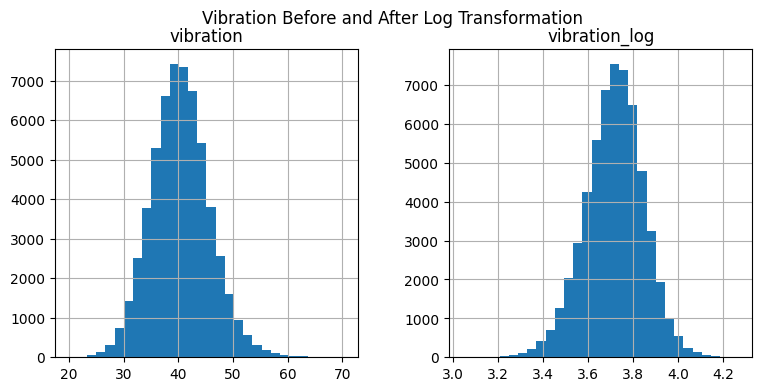

In [25]:
df[["vibration", "vibration_log"]].hist(bins=30, figsize=(9, 4))
plt.suptitle("Vibration Before and After Log Transformation")
plt.show()

## 16. Visualize the features

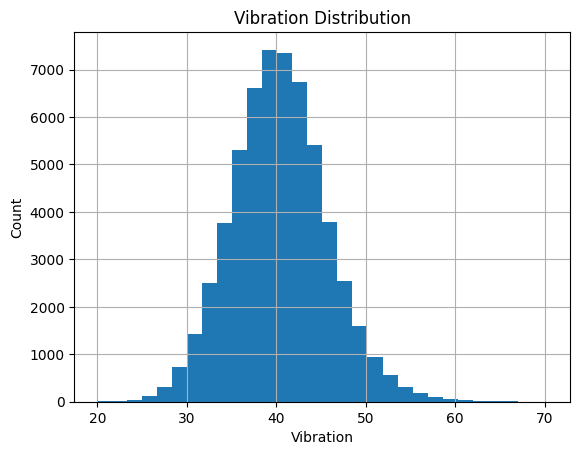

In [26]:
df["vibration"].hist(bins=30)
plt.title("Vibration Distribution")
plt.xlabel("Vibration")
plt.ylabel("Count")
plt.show()

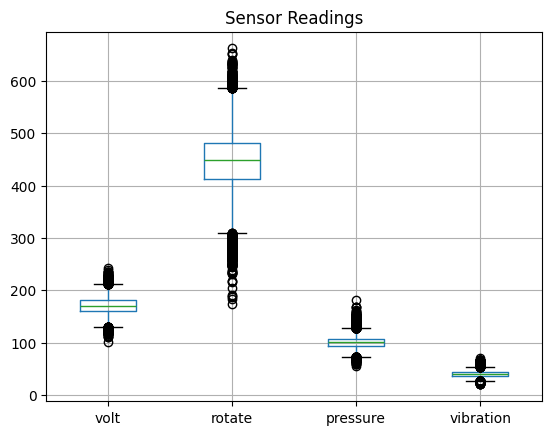

In [27]:
df[["volt", "rotate", "pressure", "vibration"]].boxplot()
plt.title("Sensor Readings")
plt.show()

In [28]:
df[["volt", "rotate", "pressure", "vibration", "age"]].corr().round(2)

,volt,rotate,pressure,vibration,age
volt,1.00,0.0,0.0,-0.00,0.01
rotate,0.00,1.0,-0.0,0.00,-0.00
pressure,0.00,-0.0,1.0,0.00,0.00
vibration,-0.00,0.0,0.0,1.00,0.02
age,0.01,-0.0,0.0,0.02,1.00


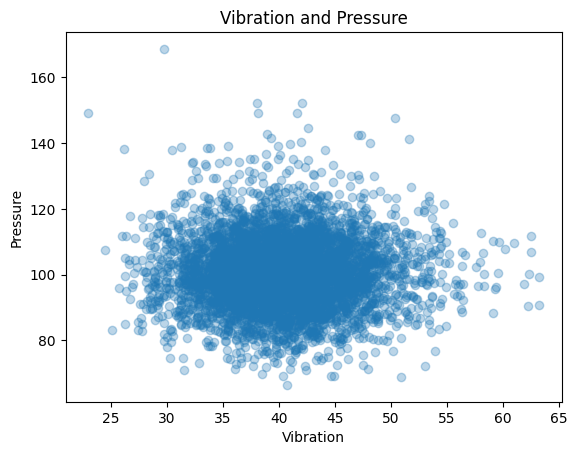

In [29]:
sample = df.sample(min(5000, len(df)), random_state=42)
plt.scatter(sample["vibration"], sample["pressure"], alpha=0.3)
plt.xlabel("Vibration")
plt.ylabel("Pressure")
plt.title("Vibration and Pressure")
plt.show()

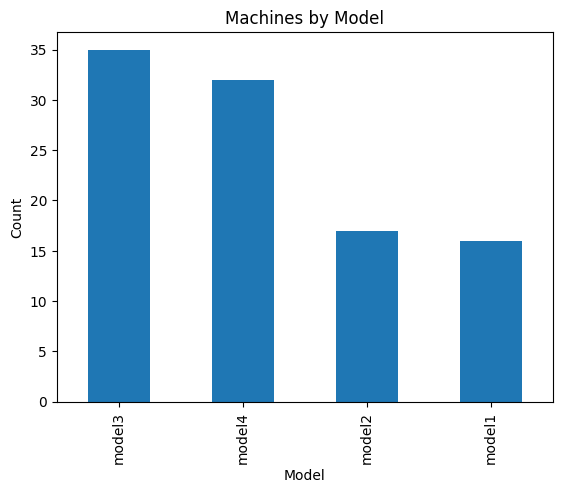

In [30]:
machines["model"].value_counts().plot(kind="bar")
plt.title("Machines by Model")
plt.xlabel("Model")
plt.ylabel("Count")
plt.show()

## 17. Check and save the prepared data

In [31]:
print("Final rows and columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df.to_csv("/content/PredictX_AI_feature_engineered.csv", index=False)
print("Saved feature-engineered dataset")

Final rows and columns: (57900, 27)
Missing values: 21
Duplicate rows: 0
Saved feature-engineered dataset


## Conclusion

I checked the data, handled missing values and duplicates, and created time, sensor, error, maintenance, and machine-age features. I also tried encoding, scaling, log transformation, and visualizations. The prepared data can now be used for a separate machine-failure prediction model. For model evaluation, the scaler should be fitted on the training data only. A failure label and a correct remaining-useful-life target must be created before training those models.

In [32]:
display(failures.head(10))

,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4
5,2015-10-17 06:00:00,1,comp2
6,2015-12-16 06:00:00,1,comp4
7,2015-03-19 06:00:00,2,comp1
8,2015-03-19 06:00:00,2,comp2
9,2015-04-18 06:00:00,2,comp2


In [33]:
print("Total failure records:", len(failures))

print("\nFailure types:")
print(failures["failure"].value_counts())

print("\nFailures by machine:")
print(failures["machineID"].value_counts().head(10))

Total failure records: 761

Failure types:
failure
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64

Failures by machine:
machineID
99    19
98    16
22    15
17    15
83    14
37    14
20    13
13    13
16    13
71    13
Name: count, dtype: int64


In [34]:
print("Telemetry date range:")
print(telemetry["datetime"].min())
print(telemetry["datetime"].max())

print("\nFailure date range:")
print(failures["datetime"].min())
print(failures["datetime"].max())

print("\nSample failure records:")
display(failures.head())

Telemetry date range:
2015-01-01 06:00:00
2016-01-01 06:00:00

Failure date range:
2015-01-02 03:00:00
2015-12-31 06:00:00

Sample failure records:


,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4


In [35]:
import pandas as pd

# Convert timestamps into datetime format
telemetry["datetime"] = pd.to_datetime(telemetry["datetime"])
failures["datetime"] = pd.to_datetime(failures["datetime"])

# Sort sensor readings by machine and time
telemetry = telemetry.sort_values(
    ["machineID", "datetime"]
).reset_index(drop=True)

# Sort failure records by machine and time
failures = failures.sort_values(
    ["machineID", "datetime"]
).reset_index(drop=True)

print("Telemetry time range:")
print(telemetry["datetime"].min(), "to", telemetry["datetime"].max())

print("\nFailure time range:")
print(failures["datetime"].min(), "to", failures["datetime"].max())

print("\nTelemetry records:", len(telemetry))
print("Failure records:", len(failures))

Telemetry time range:
2015-01-01 06:00:00 to 2016-01-01 06:00:00

Failure time range:
2015-01-02 03:00:00 to 2015-12-31 06:00:00

Telemetry records: 57900
Failure records: 761


In [36]:
import numpy as np
import pandas as pd

# Ensure timestamps use datetime format
telemetry["datetime"] = pd.to_datetime(telemetry["datetime"])
failures["datetime"] = pd.to_datetime(failures["datetime"])

# Sort records chronologically
telemetry = telemetry.sort_values(
    ["machineID", "datetime"]
).reset_index(drop=True)

failures = failures.sort_values(
    ["machineID", "datetime"]
).reset_index(drop=True)

# Create the target column
telemetry["failure_next_24h"] = 0

# Label readings that occur within 24 hours before a recorded failure
for machine_id, machine_failures in failures.groupby("machineID"):
    machine_mask = telemetry["machineID"] == machine_id
    reading_times = telemetry.loc[machine_mask, "datetime"]

    for failure_time in machine_failures["datetime"]:
        time_difference = failure_time - reading_times

        valid = (
            (time_difference > pd.Timedelta(0)) &
            (time_difference <= pd.Timedelta(hours=24))
        )

        telemetry.loc[reading_times.index[valid], "failure_next_24h"] = 1

# Display label counts
print("Target label distribution:")
print(telemetry["failure_next_24h"].value_counts())

print("\nTarget label percentages:")
print(
    telemetry["failure_next_24h"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(telemetry.head())

Target label distribution:
failure_next_24h
0    57084
1      816
Name: count, dtype: int64

Target label percentages:
failure_next_24h
0    98.59
1     1.41
Name: proportion, dtype: float64


,datetime,machineID,volt,rotate,pressure,vibration,failure_next_24h
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,0
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,0
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,0
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,0
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,0


In [37]:
print("Target column:", "failure_next_24h" in telemetry.columns)

print("\nMissing target labels:")
print(telemetry["failure_next_24h"].isnull().sum())

print("\nTarget values:")
print(telemetry["failure_next_24h"].value_counts())

print("\nInvalid labels:")
print((~telemetry["failure_next_24h"].isin([0, 1])).sum())

Target column: True

Missing target labels:
0

Target values:
failure_next_24h
0    57084
1      816
Name: count, dtype: int64

Invalid labels:
0


In [38]:
print("Target column exists:", "failure_next_24h" in telemetry.columns)

print("Missing labels:", telemetry["failure_next_24h"].isnull().sum())

print("\nTarget distribution:")
print(telemetry["failure_next_24h"].value_counts())

print("\nInvalid labels:", (~telemetry["failure_next_24h"].isin([0, 1])).sum())


Target column exists: True
Missing labels: 0

Target distribution:
failure_next_24h
0    57084
1      816
Name: count, dtype: int64

Invalid labels: 0


In [39]:
X = telemetry[["volt", "rotate", "pressure", "vibration"]]

y = telemetry["failure_next_24h"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (57900, 4)
Target shape: (57900,)


In [40]:
split = int(len(telemetry) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (46320, 4)
Testing data: (11580, 4)


In [41]:
print("Missing values in training data:")
print(X_train.isnull().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum())

Missing values in training data:
volt         0
rotate       0
pressure     0
vibration    0
dtype: int64

Missing values in testing data:
volt         0
rotate       0
pressure     0
vibration    0
dtype: int64


In [42]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [43]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
[0 0 0 0 0 0 0 0 0 0]


In [44]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.75647668393782 %


In [45]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[11436     0]
 [  144     0]]


In [46]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     11436
           1       0.00      0.00      0.00       144

    accuracy                           0.99     11580
   macro avg       0.49      0.50      0.50     11580
weighted avg       0.98      0.99      0.98     11580



In [47]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight="balanced", max_iter=1000)

model.fit(X_train, y_train)

print("Balanced model training completed!")

Balanced model training completed!


In [48]:
y_pred = model.predict(X_test)

from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred))

[[8037 3399]
 [  43  101]]


In [49]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

Precision: 0.028857142857142856
Recall: 0.7013888888888888
F1 Score: 0.05543358946212953


In [50]:
y_prob = model.predict_proba(X_test)[:, 1]

y_pred_07 = (y_prob >= 0.7).astype(int)

from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_07))

[[10434  1002]
 [   88    56]]


In [51]:
from sklearn.metrics import precision_score, recall_score

print("Threshold 0.5")
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))

print("\nThreshold 0.7")
print("Precision:", precision_score(y_test, y_pred_07, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_07, zero_division=0))

Threshold 0.5
Precision: 0.028857142857142856
Recall: 0.7013888888888888

Threshold 0.7
Precision: 0.052930056710775046
Recall: 0.3888888888888889


In [52]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [53]:
rf_pred = rf_model.predict(X_test)

print("First 10 predictions:")
print(rf_pred[:10])

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]


In [54]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, rf_pred))

[[11436     0]
 [  144     0]]


In [55]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight={0: 1, 1: 10},
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Improved Random Forest training completed!")

Improved Random Forest training completed!


In [56]:
rf_pred = rf_model.predict(X_test)

print("Confusion Matrix:")

from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, rf_pred))

Confusion Matrix:
[[11436     0]
 [  144     0]]


In [57]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("First 10 failure probabilities:")
print(rf_prob[:10])

print("\nHighest failure probability:")
print(rf_prob.max())

First 10 failure probabilities:
[0.01 0.02 0.04 0.   0.   0.01 0.   0.   0.   0.02]

Highest failure probability:
0.41


In [58]:
rf_pred_03 = (rf_prob >= 0.3).astype(int)

from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, rf_pred_03))

[[11421    15]
 [  142     2]]


In [59]:
rf_pred_01 = (rf_prob >= 0.1).astype(int)

from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, rf_pred_01))

[[11106   330]
 [  125    19]]


In [60]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Precision:", precision_score(y_test, rf_pred_01, zero_division=0))
print("Recall:", recall_score(y_test, rf_pred_01, zero_division=0))
print("F1 Score:", f1_score(y_test, rf_pred_01, zero_division=0))

Precision: 0.054441260744985676
Recall: 0.13194444444444445
F1 Score: 0.07707910750507099


In [61]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Logistic Regression")
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nRandom Forest (threshold 0.1)")
print("Precision:", precision_score(y_test, rf_pred_01, zero_division=0))
print("Recall:", recall_score(y_test, rf_pred_01, zero_division=0))
print("F1 Score:", f1_score(y_test, rf_pred_01, zero_division=0))

Logistic Regression
Precision: 0.028857142857142856
Recall: 0.7013888888888888
F1 Score: 0.05543358946212953

Random Forest (threshold 0.1)
Precision: 0.054441260744985676
Recall: 0.13194444444444445
F1 Score: 0.07707910750507099


In [62]:
!pip install xgboost


In [63]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [64]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    scale_pos_weight=10,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [65]:
xgb_pred = xgb_model.predict(X_test)

print("First 10 predictions:")
print(xgb_pred[:10])


First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]


In [66]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, xgb_pred))

[[11294   142]
 [  134    10]]


In [67]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Precision:", precision_score(y_test, xgb_pred, zero_division=0))
print("Recall:", recall_score(y_test, xgb_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, xgb_pred, zero_division=0))

Precision: 0.06578947368421052
Recall: 0.06944444444444445
F1 Score: 0.06756756756756757


In [68]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("LOGISTIC REGRESSION")
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nRANDOM FOREST (Threshold 0.1)")
print("Precision:", precision_score(y_test, rf_pred_01, zero_division=0))
print("Recall:", recall_score(y_test, rf_pred_01, zero_division=0))
print("F1 Score:", f1_score(y_test, rf_pred_01, zero_division=0))

print("\nXGBOOST")
print("Precision:", precision_score(y_test, xgb_pred, zero_division=0))
print("Recall:", recall_score(y_test, xgb_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, xgb_pred, zero_division=0))

LOGISTIC REGRESSION
Precision: 0.028857142857142856
Recall: 0.7013888888888888
F1 Score: 0.05543358946212953

RANDOM FOREST (Threshold 0.1)
Precision: 0.054441260744985676
Recall: 0.13194444444444445
F1 Score: 0.07707910750507099

XGBOOST
Precision: 0.06578947368421052
Recall: 0.06944444444444445
F1 Score: 0.06756756756756757


In [69]:
print("First 10 failure probabilities:")
print(xgb_model.predict_proba(X_test)[:10, 1])

First 10 failure probabilities:
[0.0274309  0.07715152 0.17353782 0.16012898 0.03537837 0.14447553
 0.01995421 0.01174576 0.02498863 0.2468588 ]


# Activity No. 1 — Machine Learning Classification and Regression
## Continuation of the existing PredictX AI notebook

**Important:** The cells above are your original work. They have been preserved without editing. The following cells continue after your last XGBoost probability cell and reuse your existing datasets and feature-engineered `df`.

This activity covers:
- Classification: predict `failure_next_24h`.
- Regression: predict the average vibration during the next 24 hours.
- Model training, evaluation, comparison, threshold tuning, prediction demo, and saving models.

We will use small code cells. Run these new cells from top to bottom.

## A1. Finish XGBoost threshold evaluation

In [70]:
# Use the XGBoost probabilities already calculated by your model
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

# Try a lower threshold of 0.1
xgb_pred_01 = (xgb_prob >= 0.1).astype(int)

from sklearn.metrics import confusion_matrix
print("XGBoost — threshold 0.1")
print(confusion_matrix(y_test, xgb_pred_01))

XGBoost — threshold 0.1
[[8281 3155]
 [  54   90]]


In [71]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Precision:", precision_score(y_test, xgb_pred_01, zero_division=0))
print("Recall:", recall_score(y_test, xgb_pred_01, zero_division=0))
print("F1 Score:", f1_score(y_test, xgb_pred_01, zero_division=0))

Precision: 0.02773497688751926
Recall: 0.625
F1 Score: 0.053113012688108585


## A2. Compare the three existing classification models

In [72]:
from sklearn.metrics import accuracy_score
import pandas as pd

classification_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    },
    {
        "Model": "Random Forest (threshold 0.1)",
        "Precision": precision_score(y_test, rf_pred_01, zero_division=0),
        "Recall": recall_score(y_test, rf_pred_01, zero_division=0),
        "F1 Score": f1_score(y_test, rf_pred_01, zero_division=0)
    },
    {
        "Model": "XGBoost (threshold 0.1)",
        "Precision": precision_score(y_test, xgb_pred_01, zero_division=0),
        "Recall": recall_score(y_test, xgb_pred_01, zero_division=0),
        "F1 Score": f1_score(y_test, xgb_pred_01, zero_division=0)
    }
])

display(classification_comparison.round(4))

,Model,Precision,Recall,F1 Score
0,Logistic Regression,0.0289,0.7014,0.0554
1,Random Forest (threshold 0.1),0.0544,0.1319,0.0771
2,XGBoost (threshold 0.1),0.0277,0.6250,0.0531


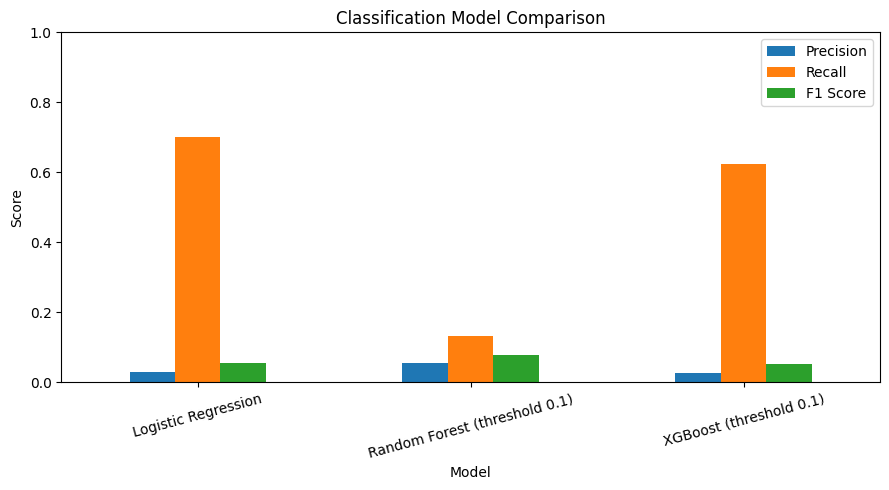

In [73]:
classification_comparison.set_index("Model")[["Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## A3. Prepare the feature-engineered data for a time-based evaluation

Your earlier experiment used an 80/20 row split after sorting by machine ID. That split is useful as an initial experiment, but it is not a true chronological test across all machines. In this additional section, we create a separate time-based evaluation while keeping your original cells and results unchanged.

We attach the existing target to the feature-engineered table using machine ID and timestamp.

In [74]:
# Attach the target created earlier to the feature-engineered dataframe
target_data = telemetry[["machineID", "datetime", "failure_next_24h"]].copy()

activity_data = df.merge(
    target_data,
    on=["machineID", "datetime"],
    how="inner"
)

activity_data = activity_data.sort_values("datetime").reset_index(drop=True)

print("Activity dataset shape:", activity_data.shape)
print("Target distribution:")
display(activity_data["failure_next_24h"].value_counts())

Activity dataset shape: (57900, 28)
Target distribution:


,count
failure_next_24h,
0,57084
1,816


## A4. Select classification features

In [75]:
# Use original sensor values and engineered features.
# Exclude total error/maintenance counts and full-dataset scaled columns
# because they can contain information from outside an individual time point.
feature_columns = [
    "volt", "rotate", "pressure", "vibration", "age",
    "hour", "day_of_week", "month",
    "vibration_change", "pressure_change", "rotation_change",
    "vibration_log"
]

# Add one-hot machine-model columns created in your feature engineering section
model_columns = [c for c in activity_data.columns if c.startswith("model_")]
feature_columns = feature_columns + model_columns

print("Number of selected features:", len(feature_columns))
print(feature_columns)

Number of selected features: 14
['volt', 'rotate', 'pressure', 'vibration', 'age', 'hour', 'day_of_week', 'month', 'vibration_change', 'pressure_change', 'rotation_change', 'vibration_log', 'model_model3', 'model_model4']


## A5. Create chronological training, validation, and test sets

In [76]:
# Split by timestamp: first 70% for training, next 15% for validation, last 15% for testing
all_dates = np.sort(activity_data["datetime"].dropna().unique())

train_date = pd.Timestamp(all_dates[int(len(all_dates) * 0.70)])
test_date = pd.Timestamp(all_dates[int(len(all_dates) * 0.85)])

# Leave a 24-hour gap before validation and test to reduce target-window overlap
train_part = activity_data[
    activity_data["datetime"] < train_date - pd.Timedelta(hours=24)
].copy()

validation_part = activity_data[
    (activity_data["datetime"] >= train_date) &
    (activity_data["datetime"] < test_date - pd.Timedelta(hours=24))
].copy()

test_part = activity_data[
    activity_data["datetime"] >= test_date
].copy()

X_train_time = train_part[feature_columns]
y_train_time = train_part["failure_next_24h"].astype(int)

X_val_time = validation_part[feature_columns]
y_val_time = validation_part["failure_next_24h"].astype(int)

X_test_time = test_part[feature_columns]
y_test_time = test_part["failure_next_24h"].astype(int)

print("Training rows:", len(train_part))
print("Validation rows:", len(validation_part))
print("Testing rows:", len(test_part))

Training rows: 41982
Validation rows: 7740
Testing rows: 7890


In [77]:
print("Training failure labels:", y_train_time.sum())
print("Validation failure labels:", y_val_time.sum())
print("Testing failure labels:", y_test_time.sum())

if y_train_time.nunique() < 2 or y_val_time.nunique() < 2 or y_test_time.nunique() < 2:
    print("Warning: at least one time period has only one target class. Review the split before interpreting scores.")

Training failure labels: 624
Validation failure labels: 96
Testing failure labels: 96


## A6. Prepare classification preprocessing

In [78]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

classification_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Classification preprocessing is ready.")

Classification preprocessing is ready.


## A7. Train classification models on the time-based training data

In [79]:
time_classifiers = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

try:
    from xgboost import XGBClassifier
    positive = max(int(y_train_time.sum()), 1)
    negative = int((y_train_time == 0).sum())
    time_classifiers["XGBoost"] = XGBClassifier(
        n_estimators=100,
        max_depth=4,
        scale_pos_weight=negative / positive,
        random_state=42,
        eval_metric="logloss"
    )
except ImportError:
    print("XGBoost is not installed; the other classifiers will still run.")

time_classification_models = {}

for name, algorithm in time_classifiers.items():
    pipeline = Pipeline([
        ("imputer_scaler", classification_preprocessor),
        ("model", algorithm)
    ])
    pipeline.fit(X_train_time, y_train_time)
    time_classification_models[name] = pipeline
    print(name, "training completed.")

Logistic Regression training completed.
Random Forest training completed.
XGBoost training completed.


## A8. Evaluate classification models

In [80]:
from sklearn.metrics import average_precision_score

time_classification_results = []

for name, pipeline in time_classification_models.items():
    probability = pipeline.predict_proba(X_test_time)[:, 1]
    prediction = (probability >= 0.5).astype(int)

    time_classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_time, prediction),
        "Precision": precision_score(y_test_time, prediction, zero_division=0),
        "Recall": recall_score(y_test_time, prediction, zero_division=0),
        "F1 Score": f1_score(y_test_time, prediction, zero_division=0),
        "PR-AUC": average_precision_score(y_test_time, probability)
    })

time_classification_results = pd.DataFrame(time_classification_results)
display(time_classification_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Logistic Regression,0.9241,0.0641,0.3854,0.11,0.0515
1,Random Forest,0.9877,0.0000,0.0000,0.00,0.0574
2,XGBoost,0.9695,0.0994,0.1875,0.13,0.0571


In [81]:
# Show confusion matrix and classification report for each model
for name, pipeline in time_classification_models.items():
    probability = pipeline.predict_proba(X_test_time)[:, 1]
    prediction = (probability >= 0.5).astype(int)

    print("\n", name)
    print("Confusion matrix:")
    print(confusion_matrix(y_test_time, prediction))
    print(classification_report(y_test_time, prediction, zero_division=0))


 Logistic Regression
Confusion matrix:
[[7254  540]
 [  59   37]]
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      7794
           1       0.06      0.39      0.11        96

    accuracy                           0.92      7890
   macro avg       0.53      0.66      0.54      7890
weighted avg       0.98      0.92      0.95      7890


 Random Forest
Confusion matrix:
[[7793    1]
 [  96    0]]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      7794
           1       0.00      0.00      0.00        96

    accuracy                           0.99      7890
   macro avg       0.49      0.50      0.50      7890
weighted avg       0.98      0.99      0.98      7890


 XGBoost
Confusion matrix:
[[7631  163]
 [  78   18]]
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      7794
           1       0.10      0.19      0.13        96


## A9. Tune the classification threshold using validation data

In [82]:
# Select a threshold using validation F1, not the final test data
threshold_choices = np.arange(0.05, 0.96, 0.05)
selected_thresholds = []

for name, pipeline in time_classification_models.items():
    val_probability = pipeline.predict_proba(X_val_time)[:, 1]

    best_threshold = 0.5
    best_validation_f1 = -1

    for threshold in threshold_choices:
        val_prediction = (val_probability >= threshold).astype(int)
        score = f1_score(y_val_time, val_prediction, zero_division=0)

        if score > best_validation_f1:
            best_validation_f1 = score
            best_threshold = threshold

    selected_thresholds.append({
        "Model": name,
        "Threshold": float(best_threshold),
        "Validation F1": best_validation_f1
    })

threshold_table = pd.DataFrame(selected_thresholds)
display(threshold_table.round(4))

,Model,Threshold,Validation F1
0,Logistic Regression,0.65,0.1850
1,Random Forest,0.05,0.1150
2,XGBoost,0.05,0.0808


In [83]:
# Evaluate the selected thresholds on the untouched test set
tuned_results = []

for row in selected_thresholds:
    name = row["Model"]
    threshold = row["Threshold"]
    pipeline = time_classification_models[name]

    test_probability = pipeline.predict_proba(X_test_time)[:, 1]
    test_prediction = (test_probability >= threshold).astype(int)

    tuned_results.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(y_test_time, test_prediction, zero_division=0),
        "Recall": recall_score(y_test_time, test_prediction, zero_division=0),
        "F1 Score": f1_score(y_test_time, test_prediction, zero_division=0),
        "False Alarms": int(((y_test_time == 0) & (test_prediction == 1)).sum()),
        "Missed Failures": int(((y_test_time == 1) & (test_prediction == 0)).sum())
    })

tuned_results = pd.DataFrame(tuned_results)
display(tuned_results.round(4))

,Model,Threshold,Precision,Recall,F1 Score,False Alarms,Missed Failures
0,Logistic Regression,0.65,0.0731,0.1667,0.1016,203,80
1,Random Forest,0.05,0.0670,0.2917,0.1089,390,68
2,XGBoost,0.05,0.0347,0.3750,0.0635,1001,60


# Part B — Regression
## A10. Create the regression target: future 24-hour average vibration

Regression predicts a numerical value. Here, we predict the average vibration recorded for the same machine in the 24 hours after the current reading. This is a future sensor-value prediction, not RUL.

In [84]:
# Work with each machine separately so future readings from another machine are not mixed
regression_data = activity_data.sort_values(
    ["machineID", "datetime"]
).copy()

def create_future_vibration_target(group):
    group = group.sort_values("datetime").copy()
    times = group["datetime"].values.astype("datetime64[ns]")
    values = group["vibration"].to_numpy(dtype=float)

    cumulative_sum = np.r_[0.0, np.cumsum(np.nan_to_num(values, nan=0.0))]
    cumulative_count = np.r_[0, np.cumsum(np.isfinite(values).astype(int))]

    future_average = np.full(len(group), np.nan)

    for i in range(len(group)):
        left = np.searchsorted(times, times[i], side="right")
        right = np.searchsorted(
            times, times[i] + np.timedelta64(24, "h"), side="right"
        )

        count = cumulative_count[right] - cumulative_count[left]
        if count > 0:
            total = cumulative_sum[right] - cumulative_sum[left]
            future_average[i] = total / count

    group["future_24h_avg_vibration"] = future_average
    return group

regression_data = regression_data.groupby(
    "machineID", group_keys=False
).apply(create_future_vibration_target)

print("Regression target created.")
display(regression_data[
    ["machineID", "datetime", "vibration", "future_24h_avg_vibration"]
].head())

Regression target created.


/tmp/ipykernel_436/2565332994.py:32: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(create_future_vibration_target)


,machineID,datetime,vibration,future_24h_avg_vibration
0,1,2015-01-01 06:00:00,45.087686,39.736826
13,1,2015-01-01 07:00:00,43.413973,39.419434
20,1,2015-01-01 08:00:00,34.178847,39.786670
27,1,2015-01-01 09:00:00,41.122144,39.498374
32,1,2015-01-01 10:00:00,25.990511,39.955593


## A11. Prepare regression training and testing data

In [85]:
regression_data = regression_data.dropna(
    subset=["datetime", "future_24h_avg_vibration"]
).copy()

regression_dates = np.sort(regression_data["datetime"].unique())
regression_cutoff = pd.Timestamp(
    regression_dates[int(len(regression_dates) * 0.80)]
)

reg_train = regression_data[
    regression_data["datetime"] < regression_cutoff - pd.Timedelta(hours=24)
].copy()

reg_test = regression_data[
    regression_data["datetime"] >= regression_cutoff
].copy()

X_reg_train = reg_train[feature_columns]
y_reg_train = reg_train["future_24h_avg_vibration"]

X_reg_test = reg_test[feature_columns]
y_reg_test = reg_test["future_24h_avg_vibration"]

print("Regression training rows:", len(reg_train))
print("Regression testing rows:", len(reg_test))
display(y_reg_train.describe())

Regression training rows: 47237
Regression testing rows: 10512


,future_24h_avg_vibration
count,47237.000000
mean,40.435464
std,2.018831
min,36.202199
25%,39.421697
50%,40.136422
75%,40.886116
max,58.487281


## A12. Prepare regression models

In [86]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

regression_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )
}

print("Regression algorithms are ready.")

Regression algorithms are ready.


## A13. Train regression models

In [87]:
regression_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

trained_regression_models = {}

for name, algorithm in regression_models.items():
    pipeline = Pipeline([
        ("preprocessor", regression_preprocessor),
        ("model", algorithm)
    ])
    pipeline.fit(X_reg_train, y_reg_train)
    trained_regression_models[name] = pipeline
    print(name, "training completed.")

Linear Regression training completed.
Decision Tree Regressor training completed.
Random Forest Regressor training completed.


## A14. Evaluate regression models

In [88]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regression_results = []

for name, pipeline in trained_regression_models.items():
    prediction = pipeline.predict(X_reg_test)
    mse = mean_squared_error(y_reg_test, prediction)

    regression_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_reg_test, prediction),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_reg_test, prediction)
    })

regression_results = pd.DataFrame(regression_results)
display(regression_results.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.1389,3.2102,1.7917,0.1823
1,Decision Tree Regressor,1.0570,3.0549,1.7478,0.2219
2,Random Forest Regressor,1.0538,2.8006,1.6735,0.2866


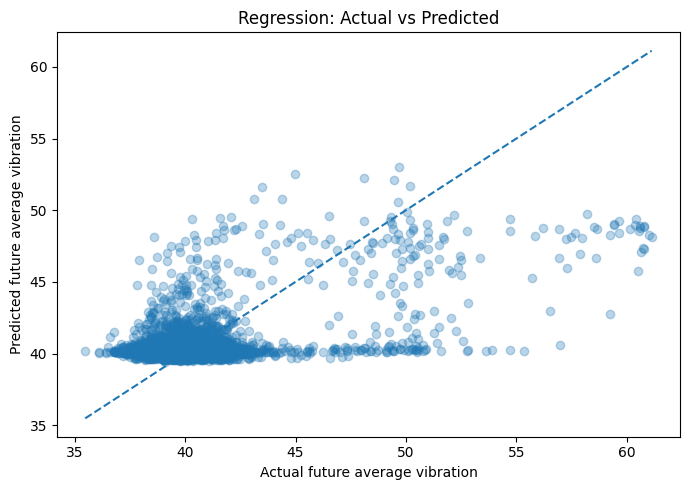

Best regression model by RMSE: Random Forest Regressor


In [89]:
# Plot actual versus predicted values for the best RMSE model
best_regression_name = regression_results.sort_values("RMSE").iloc[0]["Model"]
best_regression_model = trained_regression_models[best_regression_name]
regression_prediction = best_regression_model.predict(X_reg_test)

plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, regression_prediction, alpha=0.3)
minimum = min(y_reg_test.min(), regression_prediction.min())
maximum = max(y_reg_test.max(), regression_prediction.max())
plt.plot([minimum, maximum], [minimum, maximum], "--")
plt.xlabel("Actual future average vibration")
plt.ylabel("Predicted future average vibration")
plt.title("Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

print("Best regression model by RMSE:", best_regression_name)

## A15. Compare classification and regression results

In [90]:
print("CLASSIFICATION RESULTS")
display(tuned_results.round(4))

print("REGRESSION RESULTS")
display(regression_results.round(4))

print("Note: classification and regression scores are different metrics and should not be compared directly.")

CLASSIFICATION RESULTS


,Model,Threshold,Precision,Recall,F1 Score,False Alarms,Missed Failures
0,Logistic Regression,0.65,0.0731,0.1667,0.1016,203,80
1,Random Forest,0.05,0.0670,0.2917,0.1089,390,68
2,XGBoost,0.05,0.0347,0.3750,0.0635,1001,60


REGRESSION RESULTS


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.1389,3.2102,1.7917,0.1823
1,Decision Tree Regressor,1.0570,3.0549,1.7478,0.2219
2,Random Forest Regressor,1.0538,2.8006,1.6735,0.2866


Note: classification and regression scores are different metrics and should not be compared directly.


## A16. Save the trained models

In [91]:
from pathlib import Path
import joblib

Path("PredictX_AI_Models").mkdir(exist_ok=True)

# Select classifier by highest test F1 after validation threshold selection
best_classifier_row = tuned_results.sort_values(
    "F1 Score", ascending=False
).iloc[0]

best_classifier_name = best_classifier_row["Model"]

joblib.dump(
    time_classification_models[best_classifier_name],
    "PredictX_AI_Models/best_failure_classifier.pkl"
)

joblib.dump(
    best_regression_model,
    "PredictX_AI_Models/best_vibration_regressor.pkl"
)

print("Saved classifier:", best_classifier_name)
print("Saved regressor:", best_regression_name)

Saved classifier: Random Forest
Saved regressor: Random Forest Regressor


## A17. Demonstrate predictions on sample records

In [92]:
# Classification demo
sample_classification = X_test_time.head(5)
chosen_threshold = float(
    best_classifier_row["Threshold"]
)

sample_probability = time_classification_models[
    best_classifier_name
].predict_proba(sample_classification)[:, 1]

sample_label = (sample_probability >= chosen_threshold).astype(int)

display(pd.DataFrame({
    "Failure probability": sample_probability,
    "Predicted failure in next 24h": sample_label
}, index=sample_classification.index))

,Failure probability,Predicted failure in next 24h
50010,0.00,0
50011,0.00,0
50012,0.00,0
50013,0.02,0
50014,0.01,0


In [93]:
# Regression demo
sample_regression = X_reg_test.head(5)
sample_vibration_prediction = best_regression_model.predict(sample_regression)

display(pd.DataFrame({
    "Predicted future 24h average vibration": sample_vibration_prediction
}, index=sample_regression.index))

,Predicted future 24h average vibration
47386,40.384816
47392,42.007069
47395,40.431936
47402,40.434559
47409,40.319827


## A18. Reliability, scalability, and ethical considerations

### Reliability
- Use chronological training, validation, and testing.
- Check false alarms and missed failures, not accuracy alone.
- Monitor sensor quality, missing readings, and changes in machine behavior.
- Re-evaluate the model after retraining.

### Scalability
- Process incoming sensor data in batches or streaming windows.
- Store prediction time, machine ID, and model version.
- Monitor prediction speed and system availability.

### Ethical and operational considerations
- A prediction is an alert, not proof of a failure.
- Maintenance decisions should involve qualified staff.
- Protect machine and operational data.
- Do not use this student demonstration as the only basis for safety-critical decisions.

**Project scope:** The classification model predicts failure within 24 hours. The regression model predicts future average vibration. This regression task does not calculate Remaining Useful Life (RUL).

## A19. Activity conclusion

In Activity No. 1, the PredictX AI project demonstrates two supervised machine learning tasks.

**Classification**
- Predicts whether a machine will fail within the next 24 hours.
- Algorithms: Logistic Regression, Random Forest, and XGBoost (when installed).
- Metrics: confusion matrix, precision, recall, F1-score, and PR-AUC.

**Regression**
- Predicts average vibration during the next 24 hours.
- Algorithms: Linear Regression, Decision Tree Regressor, and Random Forest Regressor.
- Metrics: MAE, MSE, RMSE, and R² score.

The final model should be selected by considering missed failures, false alarms, and regression prediction errors.